# Lab | Time Series Analysis

## Before your start:
- Read the README.md file
- Comment as much as you can and use the resources (README.md file)
- Happy learning!

In [1]:
# Import numpy and pandas
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## Challenge 1 - Loading and Evaluating The Data

In this lab, we will look at a dataset of sensor data from a cellular phone. The phone was carried in the subject's pocket for a few minutes while they walked around.

To load the data, run the code below.

In [2]:
# Run this code:

sensor = pd.read_csv('../data/sub_1.csv')
sensor.drop(columns=['Unnamed: 0'], inplace=True)

Examine the data using the `head` function.

In [3]:
sensor.head()

,attitude.roll,attitude.pitch,attitude.yaw,gravity.x,gravity.y,gravity.z,rotationRate.x,rotationRate.y,rotationRate.z,userAcceleration.x,userAcceleration.y,userAcceleration.z
0,1.528132,-0.733896,0.696372,0.741895,0.669768,-0.031672,0.316738,0.778180,1.082764,0.294894,-0.184493,0.377542
1,1.527992,-0.716987,0.677762,0.753099,0.657116,-0.032255,0.842032,0.424446,0.643574,0.219405,0.035846,0.114866
2,1.527765,-0.706999,0.670951,0.759611,0.649555,-0.032707,-0.138143,-0.040741,0.343563,0.010714,0.134701,-0.167808
3,1.516768,-0.704678,0.675735,0.760709,0.647788,-0.041140,-0.025005,-1.048717,0.035860,-0.008389,0.136788,0.094958
4,1.493941,-0.703918,0.672994,0.760062,0.647210,-0.058530,0.114253,-0.912890,0.047341,0.199441,0.353996,-0.044299


Check whether there is any missing data. If there is any missing data, remove the rows containing missing data.

In [4]:
# Count missing values per column and drop rows with missing data (if any)
print(sensor.isna().sum().sum(), "missing values")
sensor = sensor.dropna()

0 missing values


How many rows and columns are in our data?

In [5]:
print("Rows and columns:", sensor.shape)

Rows and columns: (1751, 12)


To perform time series analysis on the data, we must change the index from a range index to a time series index. In the cell below, create a time series index using the `pd.date_range` function. Create a time series index starting at 1/1/2018 00:00:00 and ending at 1/1/2018 00:29:10. The number of periods is equal to the number of rows in `sensor`. The frequency should be set to `infer`.

In [6]:
# Newer pandas versions no longer accept freq="infer" in date_range; giving start, end and periods lets pandas infer the frequency itself
sensor_index = pd.date_range(start="1/1/2018 00:00:00", end="1/1/2018 00:29:10", periods=sensor.shape[0])
print("Inferred frequency:", sensor_index.freq)
sensor_index[:3]

Inferred frequency: None


DatetimeIndex(['2018-01-01 00:00:00', '2018-01-01 00:00:01',
               '2018-01-01 00:00:02'],
              dtype='datetime64[us]', freq=None)

Assign the time series index to the dataframe's index.

In [7]:
sensor.index = sensor_index
sensor.head(3)

,attitude.roll,attitude.pitch,attitude.yaw,gravity.x,gravity.y,gravity.z,rotationRate.x,rotationRate.y,rotationRate.z,userAcceleration.x,userAcceleration.y,userAcceleration.z
2018-01-01 00:00:00,1.528132,-0.733896,0.696372,0.741895,0.669768,-0.031672,0.316738,0.778180,1.082764,0.294894,-0.184493,0.377542
2018-01-01 00:00:01,1.527992,-0.716987,0.677762,0.753099,0.657116,-0.032255,0.842032,0.424446,0.643574,0.219405,0.035846,0.114866
2018-01-01 00:00:02,1.527765,-0.706999,0.670951,0.759611,0.649555,-0.032707,-0.138143,-0.040741,0.343563,0.010714,0.134701,-0.167808


Our next step is to decompose the time series and evaluate the patterns in the data. Load the `statsmodels.api` submodule and plot the decomposed plot of `userAcceleration.x`. Set `freq=60` in the `seasonal_decompose` function. Your graph should look like the one below.

![time series decomposition](./images/tsa_decompose.png)

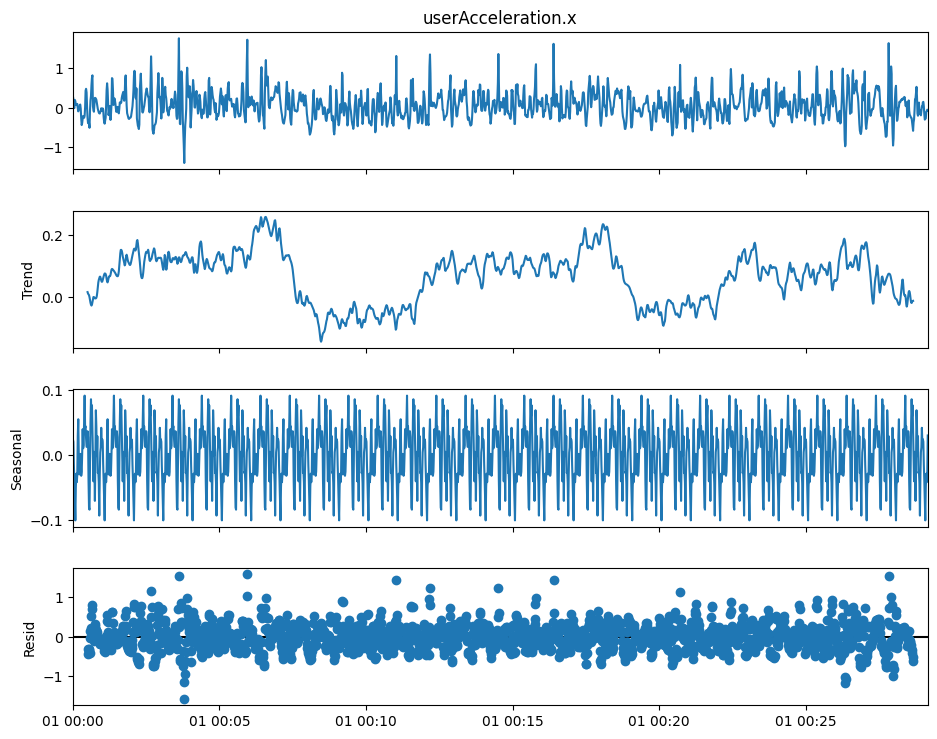

In [8]:
import statsmodels.api as sm

# newer statsmodels versions call the argument "period" instead of "freq"
decomp_acc = sm.tsa.seasonal_decompose(sensor["userAcceleration.x"], period=60)
fig = decomp_acc.plot()
fig.set_size_inches(10, 8)
plt.show()

Plot the decomposed time series of `rotationRate.x` also with a frequency of 60.

## Challenge 2 - Modelling the Data

To model our data, we should look at a few assumptions. First, let's plot the `lag_plot` to detect any autocorrelation. Do this for `userAcceleration.x`

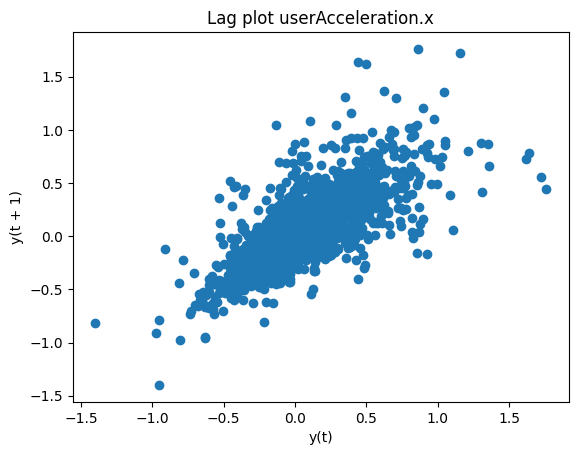

In [9]:
# Lag plot: y(t) against y(t+1). A clear pattern means autocorrelation.
from pandas.plotting import lag_plot
lag_plot(sensor["userAcceleration.x"])
plt.title("Lag plot userAcceleration.x")
plt.show()

Create a lag plot for `rotationRate.x`

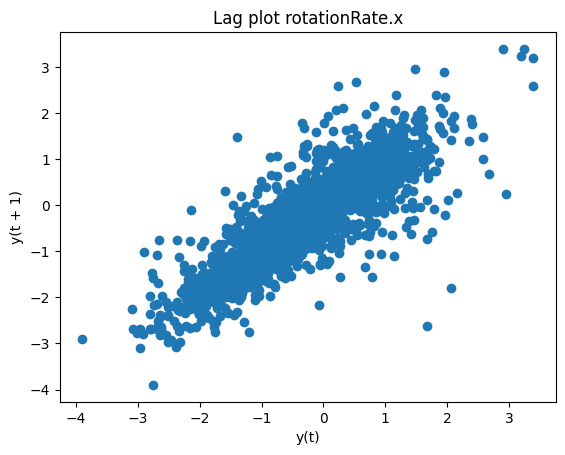

In [10]:
lag_plot(sensor["rotationRate.x"])
plt.title("Lag plot rotationRate.x")
plt.show()

What are your conclusions from both visualizations?

In [11]:
# Conclusions:
# Both lag plots show points that lie along a diagonal band, so the values are autocorrelated: the value at t is
# close to the value at t+1. The lag-1 autocorrelation is about 0.76 for userAcceleration.x and about 0.85 for
# rotationRate.x, i.e. rotationRate.x has the stronger (and more persistent) autocorrelation. This is expected for
# sensor data sampled every second while a person walks: the movement changes smoothly. Autocorrelation means an
# autoregressive model such as ARMA can make use of the past values.
print(sensor["userAcceleration.x"].autocorr(1), sensor["rotationRate.x"].autocorr(1))

0.7597036239344239 0.847090466437927


The next step will be to test both variables for stationarity. Perform the Augmented Dickey Fuller test on both variables below.

In [12]:
from statsmodels.tsa.stattools import adfuller

for col in ["userAcceleration.x", "rotationRate.x"]:
    stat, p, *_ = adfuller(sensor[col])
    print(f"{col}: ADF statistic = {stat:.3f}, p-value = {p:.4g}")

userAcceleration.x: ADF statistic = -17.958, p-value = 2.823e-30
rotationRate.x: ADF statistic = -5.270, p-value = 6.32e-06


/tmp/ipykernel_1593/1276286015.py:4: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  stat, p, *_ = adfuller(sensor[col])
/tmp/ipykernel_1593/1276286015.py:4: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  stat, p, *_ = adfuller(sensor[col])


What are your conclusions from this test?

In [13]:
# Conclusions:
# The Augmented Dickey-Fuller null hypothesis is "the series has a unit root (is not stationary)".
# Both p-values are far below 0.05 (userAcceleration.x: ~1e-30, rotationRate.x: ~6e-6), so we reject the null
# hypothesis: both series are stationary. That means we can model them with an ARMA model without differencing (d=0).

Finally, we'll create an ARMA model for `userAcceleration.x`. Load the `ARMA` function from `statsmodels`. The order of the model is (2, 1). Split the data to train and test. Use the last 10 observations as the test set and all other observations as the training set. 

In [14]:
from statsmodels.tsa.arima.model import ARIMA  # ARMA was removed from statsmodels; ARIMA with d=0 is the same model

train = sensor["userAcceleration.x"][:-10]
test = sensor["userAcceleration.x"][-10:]
arma_model = ARIMA(train, order=(2, 0, 1)).fit()
predictions = arma_model.forecast(steps=10)
print(arma_model.summary().tables[1])

/usr/local/lib/python3.11/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency s will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.11/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency s will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.11/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency s will be used.
  self._init_dates(dates, freq)


                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0637      0.016      3.994      0.000       0.032       0.095
ar.L1          0.9882      0.036     27.630      0.000       0.918       1.058
ar.L2         -0.3788      0.033    -11.637      0.000      -0.443      -0.315
ma.L1          0.1824      0.039      4.643      0.000       0.105       0.259
sigma2         0.0381      0.001     46.070      0.000       0.036       0.040


To compare our predictions with the observed data, we can compute the RMSE (Root Mean Squared Error) from the submodule `statsmodels.tools.eval_measures`. You can read more about this function [here](https://www.statsmodels.org/dev/generated/statsmodels.tools.eval_measures.rmse.html). Compute the RMSE for the last 10 rows of the data by comparing the observed and predicted data for the `userAcceleration.x` column.

In [15]:
from statsmodels.tools.eval_measures import rmse

print("RMSE:", rmse(test, predictions))
print("Std of the test data for comparison:", test.std())
# The RMSE (~0.23) is larger than the standard deviation of the test data (~0.14). An ARMA(2,1) forecast over 10 steps
# reverts quickly to the mean, so it is not better than simply predicting the average for such a noisy walking signal.

RMSE: 0.2252916044995408
Std of the test data for comparison: 0.143932387825403
